# ЯНДЕКС.АФИША: исследовательский анализ данных

**Автор:** Карташов Владимир

**Дата:** 18.11.2025

**Ревизия:** 09.11.2026 — исправлена конвертация тенге в рубли, исключены аномальные загрузки заказов, пересчитаны все выводы.

## Цель проекта

Провести исследовательский анализ данных и выявить изменения пользовательского спроса за период с 1 июня по 31 октября 2024 года: какие события, площадки и билетные операторы привлекают аудиторию и как меняется спрос по сезонам. Отдельно проверить две гипотезы: пользователи мобильных устройств делают больше заказов, чем пользователи десктопа, и интервал между заказами у мобильных пользователей больше.

## Описание данных

**final_tickets_orders_df.csv** — все заказы билетов с двух типов устройств:

- `order_id` — идентификатор заказа;
- `user_id` — идентификатор пользователя;
- `created_dt_msk`, `created_ts_msk` — дата и дата-время создания заказа (московское время);
- `event_id` — идентификатор мероприятия;
- `cinema_circuit` — сеть кинотеатров, `нет` — если неприменимо;
- `age_limit` — возрастной рейтинг мероприятия (0+, 6+, 12+, 16+, 18+), а не возраст покупателя;
- `currency_code` — валюта оплаты (`rub`, `kzt`);
- `device_type_canonical` — тип устройства (`mobile`, `desktop`);
- `revenue` — выручка от заказа в валюте заказа;
- `service_name` — билетный оператор;
- `tickets_count` — количество билетов в заказе;
- `total` — сумма заказа (отличается от `revenue`, см. раздел «Ограничения»);
- `days_since_prev` — дней с предыдущего заказа пользователя.

**final_tickets_events_df.csv** — 11 полей о мероприятиях: `event_id`, `event_name`, `event_type_description`, `event_type_main`, `organizers`, `region_name`, `city_name`, `city_id`, `venue_id`, `venue_name`, `venue_address`.

**final_tickets_tenge_df.csv** — курс тенге: `data` (дата), `nominal` (номинал, 100 тенге), `curs` (рублей за `nominal` тенге), `cdx` (код валюты).

## Стек и воспроизводимость

Python 3.11, pandas, numpy, matplotlib, seaborn, scipy. Данные читаются по публичным ссылкам, локальные копии не нужны. Зависимости — в `requirements.txt`, запуск — `pip install -r requirements.txt` и последовательное выполнение ноутбука.

## 1. Загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.unicode_minus': False,
})
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

BASE_URL = 'https://code.s3.yandex.net/datasets/'
RANDOM_STATE = 42

In [2]:
orders = pd.read_csv(BASE_URL + 'final_tickets_orders_df.csv')
events = pd.read_csv(BASE_URL + 'final_tickets_events_df.csv')
tenge = pd.read_csv(BASE_URL + 'final_tickets_tenge_df.csv')

print(f'orders: {orders.shape[0]:,} строк, {orders.shape[1]} столбцов')
print(f'events: {events.shape[0]:,} строк, {events.shape[1]} столбцов')
print(f'tenge:  {tenge.shape[0]:,} строк, {tenge.shape[1]} столбца')

orders: 290,849 строк, 14 столбцов
events: 22,427 строк, 11 столбцов
tenge:  357 строк, 4 столбца


In [3]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   order_id               290849 non-null  int64  
 1   user_id                290849 non-null  object 
 2   created_dt_msk         290849 non-null  object 
 3   created_ts_msk         290849 non-null  object 
 4   event_id               290849 non-null  int64  
 5   cinema_circuit         290849 non-null  object 
 6   age_limit              290849 non-null  int64  
 7   currency_code          290849 non-null  object 
 8   device_type_canonical  290849 non-null  object 
 9   revenue                290849 non-null  float64
 10  service_name           290849 non-null  object 
 11  tickets_count          290849 non-null  int64  
 12  total                  290849 non-null  float64
 13  days_since_prev        268909 non-null  float64
dtypes: float64(3), int64(4), object(7)
m

В таблице заказов 290 849 строк и 14 столбцов. Пропуски есть только в `days_since_prev` — 21 940 значений, и это ровно число уникальных пользователей: пропуск структурный, он означает первый заказ пользователя в выгрузке, а не отсутствие данных. Два столбца с датами хранятся как строки.

In [4]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22427 entries, 0 to 22426
Data columns (total 11 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   event_id                22427 non-null  int64 
 1   event_name              22427 non-null  object
 2   event_type_description  22427 non-null  object
 3   event_type_main         22427 non-null  object
 4   organizers              22427 non-null  object
 5   region_name             22427 non-null  object
 6   city_name               22427 non-null  object
 7   city_id                 22427 non-null  int64 
 8   venue_id                22427 non-null  int64 
 9   venue_name              22427 non-null  object
 10  venue_address           22427 non-null  object
dtypes: int64(3), object(8)
memory usage: 1.9+ MB


В таблице событий 22 427 строк и 11 столбцов, пропусков нет. Обратите внимание на `organizers`: там обезличенные идентификаторы вида `№4893`, а не названия организаций.

In [5]:
tenge.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.94,kzt
1,2024-01-11,100,19.73,kzt
2,2024-01-12,100,19.58,kzt
3,2024-01-13,100,19.45,kzt
4,2024-01-14,100,19.45,kzt


В таблице курса `curs` — это рублей за `nominal` тенге, где `nominal = 100` (например, 19.94 ₽ за 100 тенге). Это ключевой момент для конвертации: **рубли = тенге × curs / nominal**.

## 2. Предобработка данных

### 2.1 Объединение таблиц и пропуски

In [6]:
EVENT_TEXT_COLS = [
    'event_name', 'event_type_description', 'event_type_main', 'organizers',
    'region_name', 'city_name', 'venue_name', 'venue_address',
]

frame = orders.merge(events, on='event_id', how='left', validate='m:1')
print(f'строк до объединения: {len(orders):,}; после: {len(frame):,}')

frame[EVENT_TEXT_COLS] = frame[EVENT_TEXT_COLS].fillna('unknown')
frame[['city_id', 'venue_id']] = frame[['city_id', 'venue_id']].fillna(-1).astype('int32')

unmatched = frame['event_name'].eq('unknown')
print(f'заказов без мероприятия в events: {unmatched.sum():,} '
      f'({unmatched.mean():.2%}), уникальных event_id: {frame.loc[unmatched, "event_id"].nunique()}')

строк до объединения: 290,849; после: 290,849


заказов без мероприятия в events: 238 (0.08%), уникальных event_id: 19


In [7]:
na_share = pd.DataFrame({
    'Количество пропусков': frame.isna().sum(),
    'Доля пропусков, %': (frame.isna().mean() * 100).round(2),
})
display(na_share[na_share['Количество пропусков'] > 0])

,Количество пропусков,"Доля пропусков, %"
days_since_prev,21940,7.54


`validate='m:1'` подтверждает, что `event_id` в таблице событий уникален и объединение не размножило строки. 238 заказов (0.08 %) ссылаются на 19 `event_id`, которых нет в `events`: текстовые поля для них заполнены `unknown`, идентификаторы — `-1`. Остальные 21 940 пропусков — структурные пропуски `days_since_prev`.

### 2.2 Типы данных

In [8]:
frame['created_dt_msk'] = pd.to_datetime(frame['created_dt_msk'])
frame['created_ts_msk'] = pd.to_datetime(frame['created_ts_msk'])

INT_COLS = ['order_id', 'event_id', 'age_limit', 'tickets_count', 'city_id', 'venue_id']
FLOAT_COLS = ['revenue', 'total', 'days_since_prev']

for col in INT_COLS:
    frame[col] = pd.to_numeric(frame[col], downcast='integer')
for col in FLOAT_COLS:
    frame[col] = pd.to_numeric(frame[col], downcast='float')

frame.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290849 entries, 0 to 290848
Data columns (total 24 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   order_id                290849 non-null  int32         
 1   user_id                 290849 non-null  object        
 2   created_dt_msk          290849 non-null  datetime64[ns]
 3   created_ts_msk          290849 non-null  datetime64[ns]
 4   event_id                290849 non-null  int32         
 5   cinema_circuit          290849 non-null  object        
 6   age_limit               290849 non-null  int8          
 7   currency_code           290849 non-null  object        
 8   device_type_canonical   290849 non-null  object        
 9   revenue                 290849 non-null  float64       
 10  service_name            290849 non-null  object        
 11  tickets_count           290849 non-null  int8          
 12  total                   290849

Даты приведены к `datetime64`, идентификаторы и счётчики — к минимально достаточной целочисленной разрядности, суммы — к `float32`.

### 2.3 Дубликаты

In [9]:
ORDER_COLS = [
    'order_id', 'user_id', 'created_dt_msk', 'created_ts_msk', 'event_id',
    'cinema_circuit', 'age_limit', 'currency_code', 'device_type_canonical',
    'revenue', 'service_name', 'tickets_count', 'total', 'days_since_prev',
]
KEY_COLS = [col for col in ORDER_COLS if col != 'order_id'] + EVENT_TEXT_COLS + ['city_id', 'venue_id']

dups = frame.duplicated(subset=KEY_COLS, keep='first')
dup_groups = frame[frame.duplicated(subset=KEY_COLS, keep=False)].drop_duplicates(subset=KEY_COLS).shape[0]
print(f'полных дубликатов: {frame.duplicated().sum()}')
print(f'неявных дубликатов: {dup_groups} групп, {dups.sum()} лишних строк')

frame = frame.drop_duplicates(subset=KEY_COLS, keep='first').copy()
print(f'строк после удаления: {len(frame):,}')

полных дубликатов: 0
неявных дубликатов: 28 групп, 30 лишних строк


строк после удаления: 290,819


Полных дубликатов нет. Неявные дубликаты ищем по всем полям, кроме `order_id`: 28 групп и 30 лишних строк. Это немного, но такие строки дважды попадают в суммы, поэтому оставляем по одному вхождению.

### 2.4 Приведение выручки к рублю

In [10]:
tenge['data'] = pd.to_datetime(tenge['data'])
frame = frame.merge(tenge, left_on='created_dt_msk', right_on='data', how='left', validate='m:1')

kzt_mask = frame['currency_code'].eq('kzt')
assert frame.loc[kzt_mask, 'curs'].notna().all(), 'нет курса для части заказов в тенге'

# curs — рублей за nominal тенге (nominal = 100): рубли = тенге * curs / nominal
frame['revenue_rub'] = np.where(
    kzt_mask,
    frame['revenue'] * frame['curs'] / frame['nominal'],
    frame['revenue'],
)
frame['one_ticket_revenue_rub'] = frame['revenue_rub'] / frame['tickets_count']

In [11]:
print(f'заказов в тенге: {kzt_mask.sum():,} ({kzt_mask.mean():.2%})')
print(f'доля в выручке: {frame.loc[kzt_mask, "revenue_rub"].sum() / frame["revenue_rub"].sum():.1%}')
print(f'средний чек в тенге: {frame.loc[kzt_mask, "revenue_rub"].mean():,.2f} ₽ '
      f'против {frame.loc[~kzt_mask, "revenue_rub"].mean():,.2f} ₽ в рублях')
display(frame.loc[kzt_mask, ['revenue', 'nominal', 'curs', 'revenue_rub']].head(3))

заказов в тенге: 5,069 (1.74%)
доля в выручке: 3.1%
средний чек в тенге: 981.33 ₽ против 547.59 ₽ в рублях


,revenue,nominal,curs,revenue_rub
73,518.10,100,19.01,98.50
92,347.18,100,18.93,65.73
99,328.77,100,18.60,61.15


После корректной конвертации заказы в тенге дают 3.1 % выручки и сопоставимы по среднему чеку с рублёвыми (981 ₽ против 548 ₽). Если перепутать направление курса и разделить на `curs` вместо умножения, доля тенге в выручке раздувается до 47 %, а средний чек — до 25 000 ₽: именно такая ошибка была в первой версии анализа.

### 2.5 Возвраты и выбросы

In [12]:
refunds = frame[frame['revenue_rub'] < 0]
print(f'возвратов: {len(refunds):,} на {refunds["revenue_rub"].sum():,.2f} ₽')
frame = frame[frame['revenue_rub'] >= 0].copy()

q99 = frame['revenue_rub'].quantile(0.99)
outliers = frame['revenue_rub'] > q99
print(f'99-й перцентиль выручки: {q99:,.2f} ₽; отсечено строк: {outliers.sum():,}')
frame = frame[~outliers].copy()

print(f'осталось строк: {len(frame):,}')
print(f'выручка за период: {frame["revenue_rub"].sum():,.2f} ₽')

возвратов: 381 на -949.59 ₽


99-й перцентиль выручки: 2,628.42 ₽; отсечено строк: 2,825


осталось строк: 287,613
выручка за период: 149,075,533.19 ₽


381 заказ — возвраты с отрицательной выручкой (в сумме −950 ₽). Они искажают средний чек и цены, поэтому исключены. Верхний хвост ограничен 99-м перцентилем (2 628 ₽), отсечено 2 825 строк.

### 2.6 Аномальные загрузки заказов

In [13]:
frame['hour'] = frame['created_ts_msk'].dt.hour

hourly = (frame.groupby(['created_dt_msk', 'hour']).size()
          .rename('orders').reset_index())
hourly['median_orders'] = hourly['hour'].map(hourly.groupby('hour')['orders'].median())
hourly['ratio'] = hourly['orders'] / hourly['median_orders']

batch_cells = hourly[(hourly['ratio'] > 8) & (hourly['orders'] > 200)]
display(batch_cells.sort_values('ratio', ascending=False)
        .assign(ratio=lambda d: d['ratio'].round(1))
        .reset_index(drop=True))

,created_dt_msk,hour,orders,median_orders,ratio
0,2024-10-01,11,4080,115.00,35.50
1,2024-09-03,11,3579,115.00,31.10
2,2024-10-15,8,1008,42.00,24.00
3,2024-10-31,22,1618,75.00,21.60
4,2024-10-31,21,1151,85.00,13.50
5,2024-10-31,23,543,56.00,9.70
6,2024-10-01,12,859,106.00,8.10


In [14]:
batch_index = list(zip(batch_cells['created_dt_msk'], batch_cells['hour']))
frame['is_batch'] = frame.set_index(['created_dt_msk', 'hour']).index.isin(batch_index)

print(f'строк в аномальных ячейках: {frame["is_batch"].sum():,} ({frame["is_batch"].mean():.2%})')
print('затронутые дни:', ', '.join(sorted(frame.loc[frame['is_batch'], 'created_dt_msk'].dt.strftime('%d.%m.%Y').unique())))

frame = frame[~frame['is_batch']].copy()
print(f'строк для анализа: {len(frame):,}')

строк в аномальных ячейках: 12,838 (4.46%)


затронутые дни: 01.10.2024, 03.09.2024, 15.10.2024, 31.10.2024
строк для анализа: 274,775


В четырёх днях есть часы, где число заказов в 8–35 раз выше медианы для этого часа: 3 сентября и 1 октября (11:00–12:00), 15 октября (08:00), 31 октября (21:00–23:00). Это выгрузки партнёров: 3 сентября в 11:00 пришло 3 579 заказов, почти все — спорт и один оператор, до 780 заказов на одно событие. Такие строки не отражают реальный спрос, поэтому исключены: 12 838 строк, 4.5 % выборки.

Без этой чистки один вторник 3 сентября давал «лидерство вторника» по заказам и среднему числу заказов на пользователя, а спортивные мероприятия осенью вырастали в 4 раза.

### 2.7 Итог предобработки

In [15]:
frame['month'] = frame['created_dt_msk'].dt.month
frame['month_name'] = frame['month'].map({6: 'июнь', 7: 'июль', 8: 'август', 9: 'сентябрь', 10: 'октябрь'})
frame['season'] = np.where(frame['month'].between(6, 8), 'лето', 'осень')
frame['weekday'] = frame['created_dt_msk'].dt.weekday

print(f'строк: {len(frame):,}')
print(f'период: {frame["created_dt_msk"].min():%d.%m.%Y} — {frame["created_dt_msk"].max():%d.%m.%Y}')
print(f'уникальных пользователей: {frame["user_id"].nunique():,}')
print(f'уникальных мероприятий: {frame["event_id"].nunique():,}')
print(f'выручка: {frame["revenue_rub"].sum():,.2f} ₽')

строк: 274,775
период: 01.06.2024 — 31.10.2024
уникальных пользователей: 21,682
уникальных мероприятий: 22,271
выручка: 146,712,733.13 ₽


- объединены `orders` и `events` без размножения строк;
- пропуски в событиях заполнены `unknown`, идентификаторы — `-1`; `days_since_prev` оставлен как есть, потому что пропуск означает первый заказ;
- даты приведены к `datetime`, разрядность чисел понижена;
- удалены 30 неявных дубликатов;
- выручка приведена к рублю по курсу `revenue × curs / nominal`;
- исключены 381 возврат и 2 825 строк выше 99-го перцентиля;
- исключены 12 838 строк из аномальных часовых выгрузок;
- добавлены `revenue_rub`, `one_ticket_revenue_rub`, `month`, `month_name`, `season`, `weekday`.


### 2.8 Профиль пользователей

Перед анализом «на пользователя» важно понять структуру аудитории: в выгрузке есть аккаунты с тысячами заказов, и они сильно смещают средние.


In [16]:

user_orders = frame.groupby('user_id').size().sort_values(ascending=False)
same_event_day = frame.groupby(['user_id', 'event_id', 'created_dt_msk']).size()

print(f'пользователей: {len(user_orders):,}')
print(f'заказов на пользователя: медиана {user_orders.median():.0f}, '
      f'среднее {user_orders.mean():.2f}, максимум {user_orders.max():,}')
print(f'доля заказов топ-100 пользователей: {user_orders.head(100).sum() / len(frame):.1%}')
print(f'максимум заказов одного пользователя по одному событию в день: {same_event_day.max()}')


пользователей: 21,682
заказов на пользователя: медиана 2, среднее 12.67, максимум 9,881
доля заказов топ-100 пользователей: 41.7%
максимум заказов одного пользователя по одному событию в день: 105


## 3. Исследовательский анализ данных

### 3.1 Динамика заказов по месяцам

,month,month_name,orders,revenue,"orders_share, %"
0,6,июнь,33974,"19,780,520.52",12.40
1,7,июль,40412,"22,571,768.53",14.70
2,8,август,44585,"24,324,261.10",16.20
3,9,сентябрь,65759,"32,950,795.23",23.90
4,10,октябрь,90045,"47,085,387.75",32.80


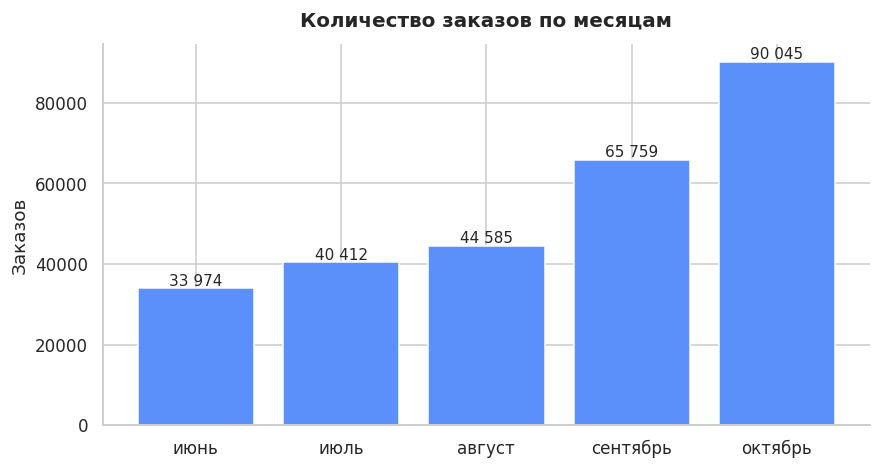

прирост сентября к августу: 47.5%
прирост октября к сентябрю: 36.9%


In [17]:
monthly = (frame.groupby(['month', 'month_name'])
           .agg(orders=('order_id', 'size'), revenue=('revenue_rub', 'sum'))
           .reset_index().sort_values('month'))
monthly['orders_share, %'] = (monthly['orders'] / monthly['orders'].sum() * 100).round(1)
display(monthly)

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(monthly['month_name'], monthly['orders'], color='#5B8FF9', edgecolor='white')
for bar, value in zip(bars, monthly['orders']):
    ax.annotate(f'{value:,}'.replace(',', ' '),
                (bar.get_x() + bar.get_width() / 2, value),
                ha='center', va='bottom', fontsize=10)
ax.set(title='Количество заказов по месяцам', xlabel='', ylabel='Заказов')
sns.despine()
plt.show()

sep_growth = monthly.loc[monthly['month'] == 9, 'orders'].iloc[0] / monthly.loc[monthly['month'] == 8, 'orders'].iloc[0] - 1
oct_growth = monthly.loc[monthly['month'] == 10, 'orders'].iloc[0] / monthly.loc[monthly['month'] == 9, 'orders'].iloc[0] - 1
print(f'прирост сентября к августу: {sep_growth:.1%}')
print(f'прирост октября к сентябрю: {oct_growth:.1%}')

Число заказов растёт каждый месяц: 33 974 в июне, 40 412 в июле, 44 585 в августе, 65 759 в сентябре (+47.5 %) и 90 045 в октябре (+36.9 %). В среднем за день: 1 132 → 1 304 → 1 438 → 2 192 → 2 905 заказов. Сентябрьский скачок — не только сезонность: после исключения аномальных выгрузок он остаётся, но часть прежнего «взрыва» в первой версии анализа была артефактом загрузки данных.

### 3.2 Типы мероприятий и сезонность

season,лето,осень
event_type_main,,
концерты,42.50,38.30
театр,20.10,27.30
другое,27.10,20.60
спорт,2.50,6.80
стендап,5.30,4.40
выставки,2.00,1.50
ёлки,0.20,1.10
unknown,0.20,0.00


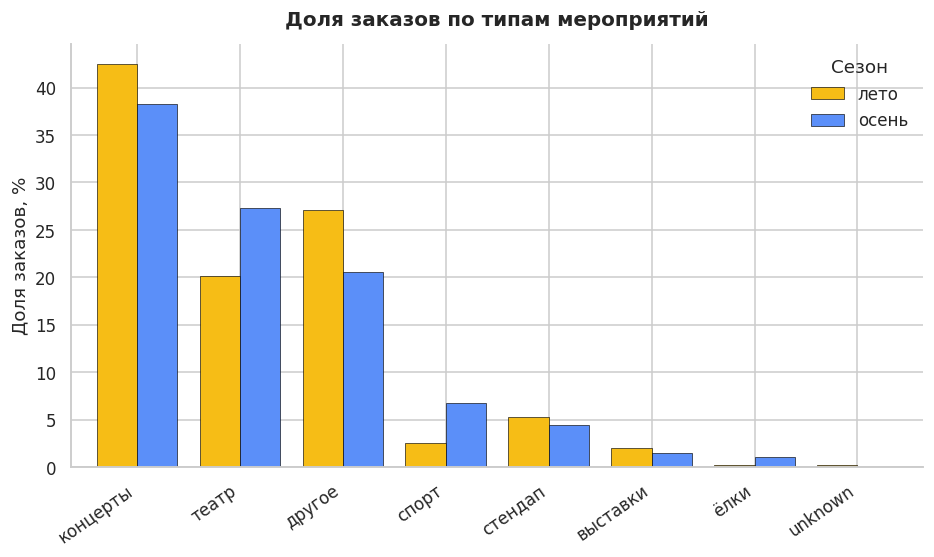

event_type_main,unknown,выставки,другое,концерты,спорт,стендап,театр,ёлки,всего
season,,,,,,,,,
лето,216,2407,32208,50558,3003,6348,23958,273,118971
осень,22,2394,32117,59626,10521,6893,42546,1685,155804


In [18]:
type_by_season = (frame.groupby(['season', 'event_type_main']).size()
                  .unstack(fill_value=0))
type_share = (type_by_season.div(type_by_season.sum(axis=1), axis=0) * 100).round(1)
type_share = type_share[type_share.loc['осень'].sort_values(ascending=False).index]
display(type_share.T)

ax = type_share.T.plot(kind='bar', figsize=(10, 5), width=0.78,
                       color=['#F6BD16', '#5B8FF9'], edgecolor='black', linewidth=0.4)
ax.set(title='Доля заказов по типам мероприятий', xlabel='', ylabel='Доля заказов, %')
ax.legend(title='Сезон', frameon=False)
plt.xticks(rotation=35, ha='right')
sns.despine()
plt.show()

display(type_by_season.assign(всего=type_by_season.sum(axis=1)))

Концерты остаются главной категорией, но их доля падает с 42.5 % летом до 38.3 % осенью. Театр растёт с 20.1 % до 27.3 %, спорт — с 2.5 % до 6.8 %, ёлки появляются осенью (1.1 %). Рост спорта заметен, но он в разы скромнее, чем показывала версия с неочищенными выгрузками (там было 11.1 %).

### 3.3 Типы устройств

device_type_canonical,desktop,mobile
season,,
лето,19.30,80.70
осень,18.40,81.60


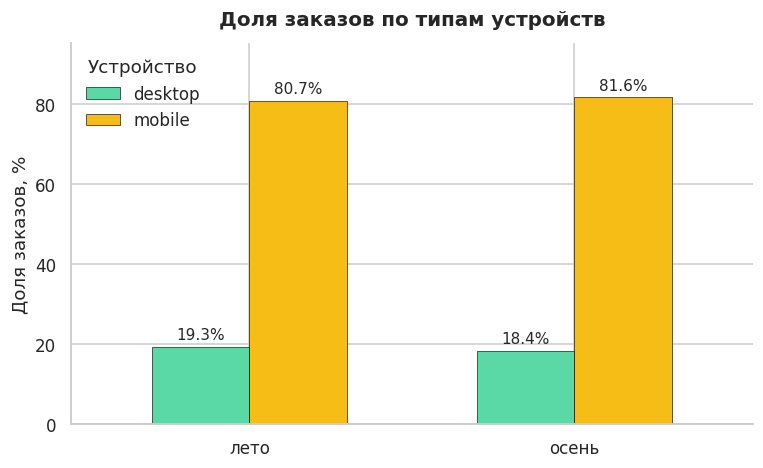

In [19]:
device_share = (frame.groupby(['season', 'device_type_canonical']).size()
                .unstack(fill_value=0))
device_share = (device_share.div(device_share.sum(axis=1), axis=0) * 100).round(1)
display(device_share)

ax = device_share.plot(kind='bar', figsize=(8, 4.5), width=0.6,
                       color=['#5AD8A6', '#F6BD16'], edgecolor='black', linewidth=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)
ax.set(title='Доля заказов по типам устройств', xlabel='', ylabel='Доля заказов, %', ylim=(0, 95))
ax.legend(title='Устройство', frameon=False)
plt.xticks(rotation=0)
sns.despine()
plt.show()

Мобильные устройства дают 80.7 % заказов летом и 81.6 % осенью — сезонность на это распределение почти не влияет, мобильный канал стабильно основной.

### 3.4 Возрастной рейтинг мероприятий

,0+,6+,12+,16+,18+
season,,,,,
лето,17.90,18.30,20.30,28.40,15.10
осень,19.60,19.00,23.80,26.40,11.20


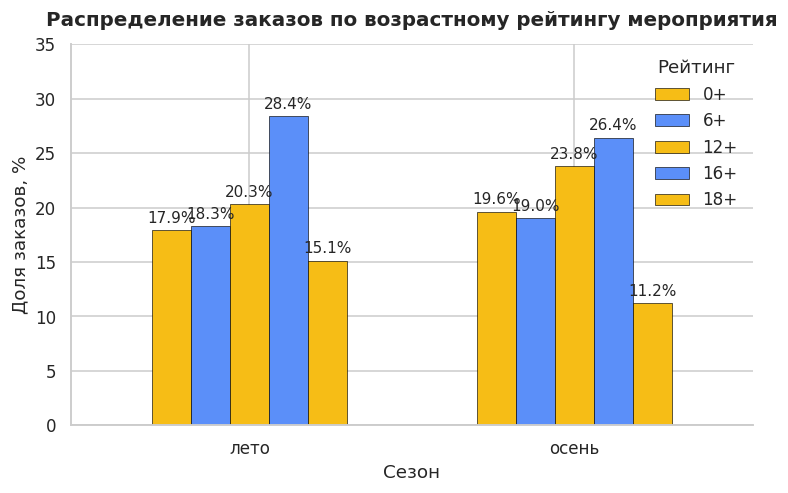

In [20]:
age_share = (frame.groupby(['season', 'age_limit']).size().unstack(fill_value=0))
age_share = (age_share.div(age_share.sum(axis=1), axis=0) * 100).round(1)
age_share.columns = [f'{age}+' for age in age_share.columns]
display(age_share)

ax = age_share.plot(kind='bar', figsize=(8, 4.5), width=0.6,
                    color=['#F6BD16', '#5B8FF9'], edgecolor='black', linewidth=0.4)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', padding=3, fontsize=10)
ax.set(title='Распределение заказов по возрастному рейтингу мероприятия',
       xlabel='Сезон', ylabel='Доля заказов, %', ylim=(0, 35))
ax.legend(title='Рейтинг', frameon=False)
plt.xticks(rotation=0)
sns.despine()
plt.show()

`age_limit` — возрастной рейтинг мероприятия, а не возраст покупателя, поэтому по этому полю корректно говорить о структуре афиши, а не о возрасте аудитории. Осенью растёт доля рейтингов 12+ (20.3 % → 23.8 %) и 0+ (17.9 % → 19.6 %), падает 18+ (15.1 % → 11.2 %): афиша становится более «семейной». Вывод первой версии о «заказах от пользователей 0–6 лет» был ошибкой интерпретации поля.

### 3.5 Цена билета по типам и сезонам

In [21]:
price = (frame.groupby(['event_type_main', 'season'])
         .agg(revenue=('revenue_rub', 'sum'), tickets=('tickets_count', 'sum'), orders=('order_id', 'size')))
price['price'] = price['revenue'] / price['tickets']
price_table = price['price'].unstack().rename(columns={'лето': 'лето, ₽', 'осень': 'осень, ₽'})
price_table['изменение, %'] = ((price_table['осень, ₽'] / price_table['лето, ₽'] - 1) * 100).round(1)
price_table = price_table.sort_values('лето, ₽', ascending=False).round(1)
display(price_table)

season,"лето, ₽","осень, ₽","изменение, %"
event_type_main,,,
концерты,299.00,277.40,-7.30
ёлки,263.50,218.80,-16.90
стендап,215.40,228.50,6.10
театр,211.70,176.70,-16.60
выставки,89.50,93.50,4.50
другое,82.70,84.00,1.60
спорт,50.70,59.50,17.30
unknown,4.10,14.60,258.60


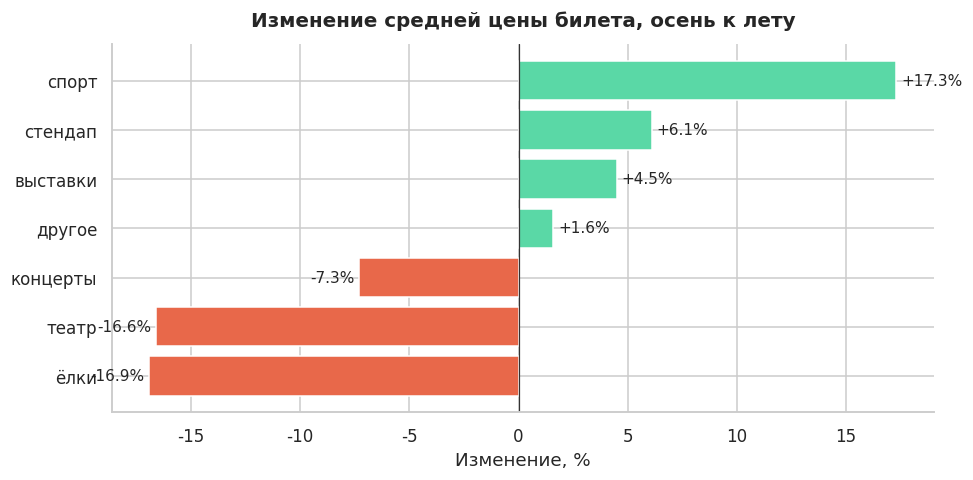

In [22]:
plot_data = price_table.drop(index='unknown').sort_values('изменение, %')
colors = ['#E8684A' if value < 0 else '#5AD8A6' for value in plot_data['изменение, %']]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(plot_data.index, plot_data['изменение, %'], color=colors)
ax.axvline(0, color='#333', linewidth=0.8)
ax.bar_label(bars, fmt='%+.1f%%', padding=3, fontsize=10)
ax.set(title='Изменение средней цены билета, осень к лету',
       xlabel='Изменение, %', ylabel='')
sns.despine()
plt.tight_layout()
plt.show()

Средняя цена билета считается как сумма выручки, делённая на число билетов — это взвешенная цена, а не среднее из отношений. Концерты подешевели умеренно: 299 ₽ → 277 ₽ (−7.3 %). Заметнее всего упали театр (212 ₽ → 177 ₽, −16.6 %) и ёлки (264 ₽ → 219 ₽, −16.9 %). Выросли спорт (+17.3 %), стендап (+6.1 %) и выставки (+4.5 %).

Именно смешение «суммы выручки» и «средней цены» давало в первой версии противоречие: театр одновременно «дешевеет» и «приносит больше выручки».

### 3.6 Выручка по типам мероприятий

season,лето,осень
event_type_main,,
концерты,59.80,54.60
театр,21.10,25.70
другое,11.10,9.20
стендап,6.20,5.80
спорт,0.70,2.40
ёлки,0.30,1.60
выставки,0.80,0.70
unknown,0.00,0.00


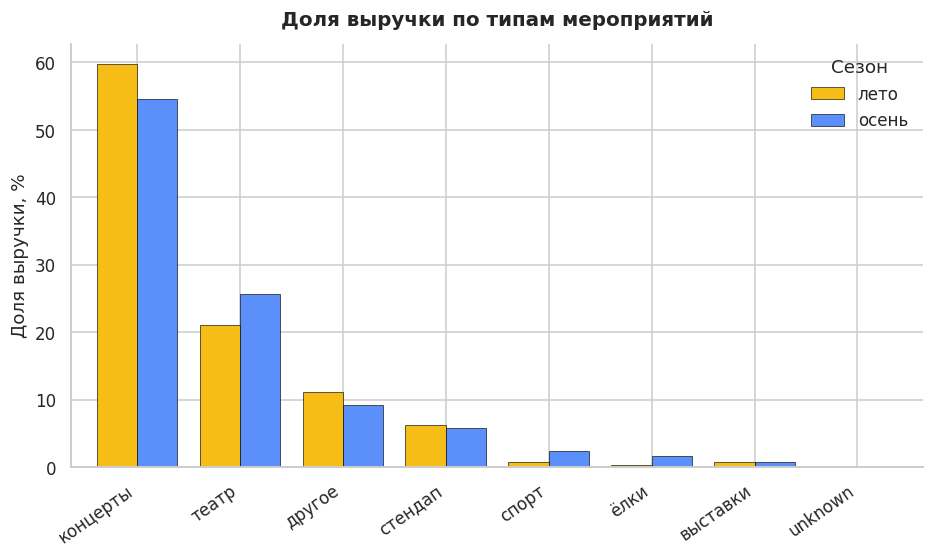

выручка лета:  66,676,550 ₽
выручка осени: 80,036,183 ₽


In [23]:
revenue_by_type = frame.groupby(['season', 'event_type_main'])['revenue_rub'].sum().unstack(fill_value=0)
revenue_share = (revenue_by_type.div(revenue_by_type.sum(axis=1), axis=0) * 100).round(1)
revenue_share = revenue_share[revenue_share.loc['осень'].sort_values(ascending=False).index]
display(revenue_share.T)

ax = revenue_share.T.plot(kind='bar', figsize=(10, 5), width=0.78,
                          color=['#F6BD16', '#5B8FF9'], edgecolor='black', linewidth=0.4)
ax.set(title='Доля выручки по типам мероприятий', xlabel='', ylabel='Доля выручки, %')
ax.legend(title='Сезон', frameon=False)
plt.xticks(rotation=35, ha='right')
sns.despine()
plt.show()

print(f'выручка лета:  {revenue_by_type.loc["лето"].sum():,.0f} ₽')
print(f'выручка осени: {revenue_by_type.loc["осень"].sum():,.0f} ₽')

Доля концертов в выручке снижается с 59.8 % до 54.6 %, театра — растёт с 21.1 % до 25.7 %, спорта — с 0.7 % до 2.4 %. Суммарная выручка осени (80.0 млн ₽) выше летней, хотя средняя цена билета падает: рост обеспечивает объём заказов, а не цена.

### 3.7 Осенняя активность пользователей

In [24]:
autumn = frame[frame['season'] == 'осень'].copy()

daily = (autumn.groupby('created_dt_msk')
         .agg(orders=('order_id', 'size'),
              users=('user_id', 'nunique'),
              revenue=('revenue_rub', 'sum'),
              tickets=('tickets_count', 'sum')))
daily['orders_per_user'] = daily['orders'] / daily['users']
daily['price_per_ticket'] = daily['revenue'] / daily['tickets']
display(daily.head(3).round(1))
display(daily.tail(3).round(1))

,orders,users,revenue,tickets,orders_per_user,price_per_ticket
created_dt_msk,,,,,,
2024-09-01,1331,565,"736,581.10",3733,2.40,197.30
2024-09-02,1376,573,"703,539.10",3695,2.40,190.40
2024-09-03,1516,632,"707,125.10",4109,2.40,172.10


,orders,users,revenue,tickets,orders_per_user,price_per_ticket
created_dt_msk,,,,,,
2024-10-29,2838,999,"1,363,371.80",7976,2.80,170.90
2024-10-30,2929,1041,"1,467,687.10",8072,2.80,181.80
2024-10-31,2651,950,"1,302,268.30",7337,2.80,177.50


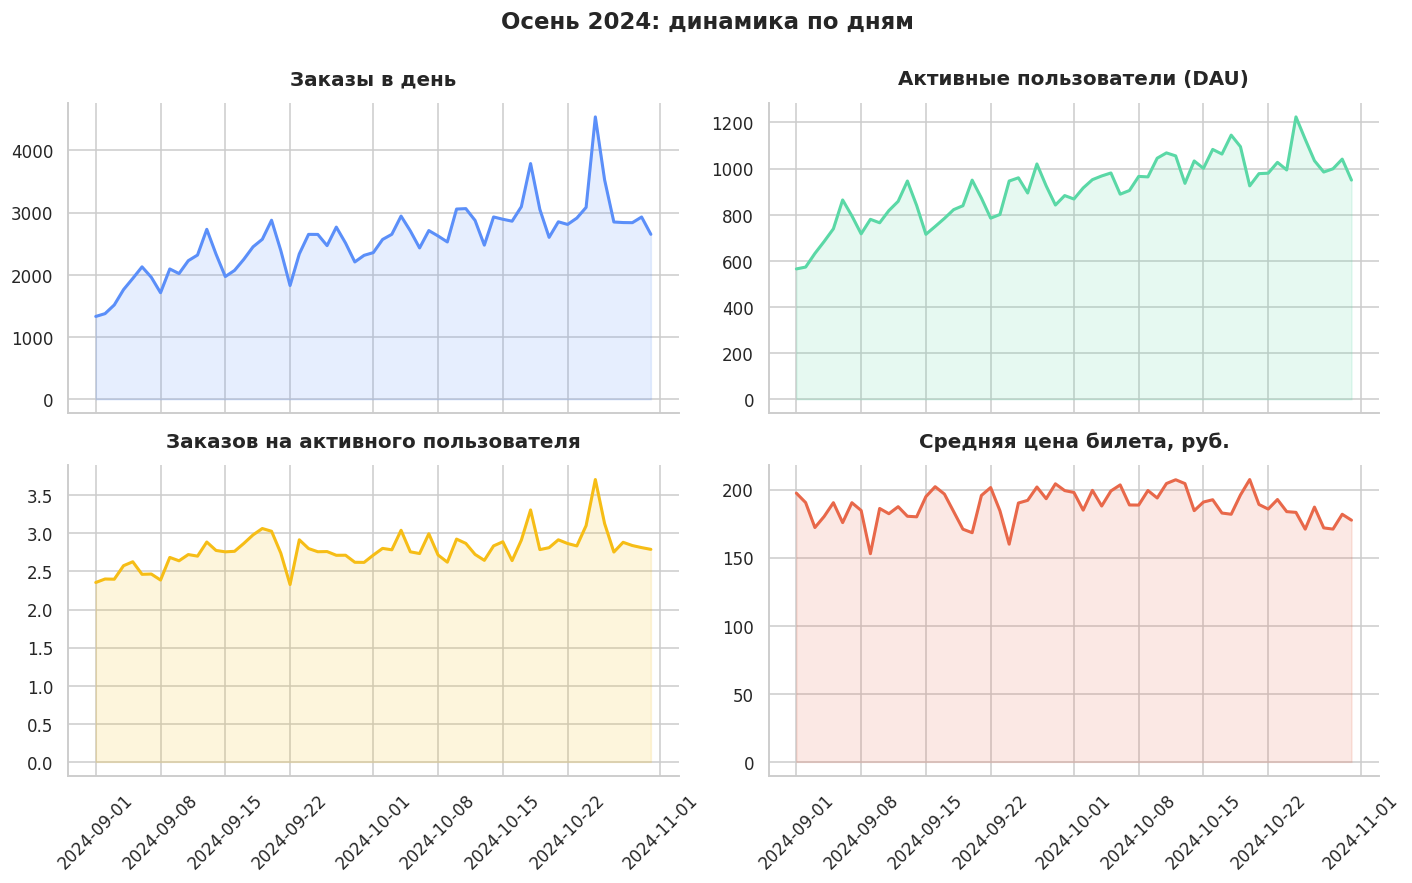

заказов в первый день осени: 1,331, в последний: 2,651
DAU: 565 → 950
максимум заказов: 4,538 (25.10.2024)
корреляция числа заказов и цены билета: -0.09


In [25]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
series = [
    ('orders', 'Заказы в день', '#5B8FF9'),
    ('users', 'Активные пользователи (DAU)', '#5AD8A6'),
    ('orders_per_user', 'Заказов на активного пользователя', '#F6BD16'),
    ('price_per_ticket', 'Средняя цена билета, руб.', '#E8684A'),
]
for ax, (column, title, color) in zip(axes.flat, series):
    ax.plot(daily.index, daily[column], color=color, linewidth=2)
    ax.fill_between(daily.index, daily[column], color=color, alpha=0.15)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=45)
    sns.despine(ax=ax)
fig.suptitle('Осень 2024: динамика по дням', fontsize=15, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

print(f'заказов в первый день осени: {daily["orders"].iloc[0]:,}, в последний: {daily["orders"].iloc[-1]:,}')
print(f'DAU: {daily["users"].iloc[0]:,} → {daily["users"].iloc[-1]:,}')
print(f'максимум заказов: {daily["orders"].max():,} ({daily["orders"].idxmax():%d.%m.%Y})')
print(f'корреляция числа заказов и цены билета: {daily["orders"].corr(daily["price_per_ticket"]):.2f}')

Осенью растут и число заказов (1 331 в первый день → 2 651 в последний), и активная аудитория (565 → 950 пользователей). Максимум — 4 538 заказов и 1 224 пользователя 25 октября; это единичный всплеск, и трактовать его как праздничный эффект по одному дню нельзя.

Корреляция числа заказов и средней цены билета близка к нулю (−0.09), поэтому тезис «пики заказов совпадают с днями со сниженной ценой» данными не подтверждается: в первой версии он возникал из-за дня с аномальной выгрузкой и смешанных валют.

### 3.8 Дни недели

,orders,users,revenue,orders_per_user,revenue_per_user
Пн,21523,4450,"10,811,960.80",4.80,"2,430.00"
Вт,21957,4558,"10,958,307.70",4.80,"2,404.00"
Ср,22887,4818,"11,597,790.10",4.80,"2,407.00"
Чт,23838,4786,"12,058,269.50",5.00,"2,519.00"
Пт,24837,4871,"12,681,425.60",5.10,"2,603.00"
Сб,21352,4570,"11,347,075.30",4.70,"2,483.00"
Вс,19410,4397,"10,581,354.00",4.40,"2,406.00"


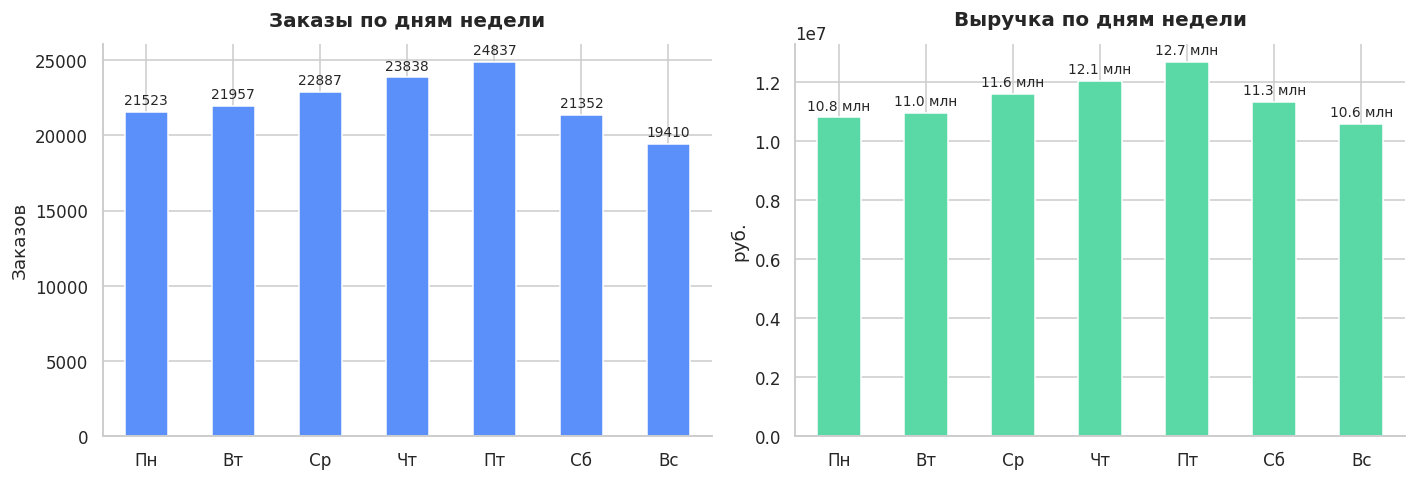

In [26]:
weekday_names = ['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс']
weekday = (autumn.groupby('weekday')
           .agg(orders=('order_id', 'size'),
                users=('user_id', 'nunique'),
                revenue=('revenue_rub', 'sum')))
weekday['orders_per_user'] = (weekday['orders'] / weekday['users']).round(2)
weekday['revenue_per_user'] = (weekday['revenue'] / weekday['users']).round(0)
weekday.index = weekday_names
display(weekday.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
weekday['orders'].plot(kind='bar', ax=axes[0], color='#5B8FF9', edgecolor='white')
axes[0].bar_label(axes[0].containers[0], fmt='%d', padding=3, fontsize=9)
axes[0].set(title='Заказы по дням недели', ylabel='Заказов', xlabel='')
weekday['revenue'].plot(kind='bar', ax=axes[1], color='#5AD8A6', edgecolor='white')
axes[1].bar_label(axes[1].containers[0], fmt='%.1f', labels=[f'{v/1e6:.1f} млн' for v in weekday['revenue']],
                  padding=3, fontsize=9)
axes[1].set(title='Выручка по дням недели', ylabel='руб.', xlabel='')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

Лидер по числу заказов — пятница (24 837), затем четверг (23 838) и среда (22 887); минимум в воскресенье (19 410). Выходные дают 26.2 % заказов при 28.6 % дней, то есть покупают скорее в будни. Выручка и выручка на пользователя тоже максимальны в пятницу (12.7 млн ₽ и 2 603 ₽). Вторник, который в первой версии был «лидером», после удаления аномальных выгрузок оказался на четвёртом месте.

### 3.9 Регионы

In [27]:
region = (autumn.groupby('region_name')
          .agg(events=('event_id', 'nunique'),
               orders=('order_id', 'size'),
               users=('user_id', 'nunique'),
               revenue=('revenue_rub', 'sum')))
region['events_share, %'] = (region['events'] / region['events'].sum() * 100).round(1)
region['orders_share, %'] = (region['orders'] / region['orders'].sum() * 100).round(1)

top_regions = region.sort_values('events', ascending=False).head(5)
display(top_regions[['events', 'events_share, %', 'orders', 'orders_share, %', 'revenue']])
print(f'всего регионов: {len(region)}')

,events,"events_share, %",orders,"orders_share, %",revenue
region_name,,,,,
Каменевский регион,3899,24.70,43814,28.10,"27,786,640.54"
Североярская область,2600,16.50,20296,13.00,"10,414,471.77"
Широковская область,793,5.00,8604,5.50,"4,197,516.51"
Светополянский округ,761,4.80,4736,3.00,"1,972,403.93"
Речиновская область,529,3.30,3547,2.30,"1,735,023.66"


всего регионов: 80


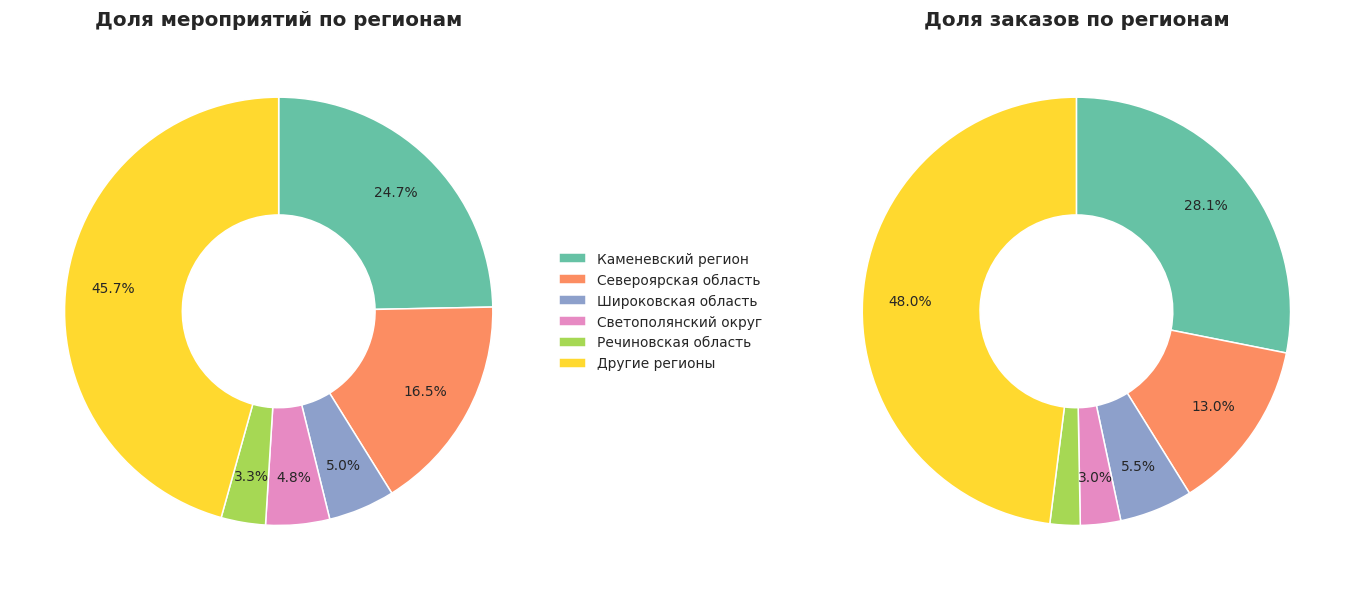

In [28]:
donut_data = pd.DataFrame({
    'Регион': list(top_regions.index) + ['Другие регионы'],
    'Мероприятия': list(top_regions['events']) + [region['events'].sum() - top_regions['events'].sum()],
    'Заказы': list(top_regions['orders']) + [region['orders'].sum() - top_regions['orders'].sum()],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
palette = sns.color_palette('Set2', n_colors=len(donut_data))
for ax, column, title in zip(axes, ['Мероприятия', 'Заказы'],
                             ['Доля мероприятий по регионам', 'Доля заказов по регионам']):
    values = donut_data[column]
    ax.pie(values, colors=palette, startangle=90, counterclock=False,
           wedgeprops={'width': 0.55, 'edgecolor': 'white'},
           autopct=lambda pct: f'{pct:.1f}%' if pct > 3 else '', pctdistance=0.78,
           textprops={'fontsize': 9})
    ax.set_title(title)
axes[0].legend(donut_data['Регион'], loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Каменевский регион — безусловный лидер: 3 899 мероприятий (24.7 % всех) и 43 814 заказов (28.1 %). Далее Североярская область (2 600 и 20 296), Широковская область (793 и 8 604), Светополянский округ (761 и 4 736), Речиновская область (529 и 3 547). На топ-5 приходится 54.3 % мероприятий и 51.9 % заказов, остальные 75 регионов делят меньшую половину. Разрыв между первым и пятым регионом — более чем семикратный по числу мероприятий.

### 3.10 Билетные операторы

In [29]:
partners = (autumn.groupby('service_name')
            .agg(events=('event_id', 'nunique'),
                 orders=('order_id', 'size'),
                 revenue=('revenue_rub', 'sum')))
for column in ['events', 'orders', 'revenue']:
    partners[f'{column}_share, %'] = (partners[column] / partners[column].sum() * 100).round(2)

print('Топ-5 по числу мероприятий')
display(partners.sort_values('events', ascending=False).head(5))
print('Топ-5 по числу заказов')
display(partners.sort_values('orders', ascending=False).head(5))
print('Топ-5 по выручке')
display(partners.sort_values('revenue', ascending=False).head(5))
print(f'всего операторов: {len(partners)}')

Топ-5 по числу мероприятий


,events,orders,revenue,"events_share, %","orders_share, %","revenue_share, %"
service_name,,,,,,
Лови билет!,3600,25610,"10,323,750.25",20.91,16.44,12.90
Билеты без проблем,2828,31411,"12,342,959.23",16.43,20.16,15.42
Билеты в руки,2454,17457,"6,643,957.37",14.26,11.20,8.30
Облачко,1407,15390,"10,546,846.07",8.17,9.88,13.18
Лучшие билеты,1385,12311,"1,664,473.35",8.05,7.90,2.08


Топ-5 по числу заказов


,events,orders,revenue,"events_share, %","orders_share, %","revenue_share, %"
service_name,,,,,,
Билеты без проблем,2828,31411,"12,342,959.23",16.43,20.16,15.42
Лови билет!,3600,25610,"10,323,750.25",20.91,16.44,12.90
Билеты в руки,2454,17457,"6,643,957.37",14.26,11.20,8.30
Мой билет,1000,16456,"10,026,775.94",5.81,10.56,12.53
Облачко,1407,15390,"10,546,846.07",8.17,9.88,13.18


Топ-5 по выручке


,events,orders,revenue,"events_share, %","orders_share, %","revenue_share, %"
service_name,,,,,,
Билеты без проблем,2828,31411,"12,342,959.23",16.43,20.16,15.42
Облачко,1407,15390,"10,546,846.07",8.17,9.88,13.18
Лови билет!,3600,25610,"10,323,750.25",20.91,16.44,12.90
Мой билет,1000,16456,"10,026,775.94",5.81,10.56,12.53
Весь в билетах,599,9383,"9,340,279.37",3.48,6.02,11.67


всего операторов: 35


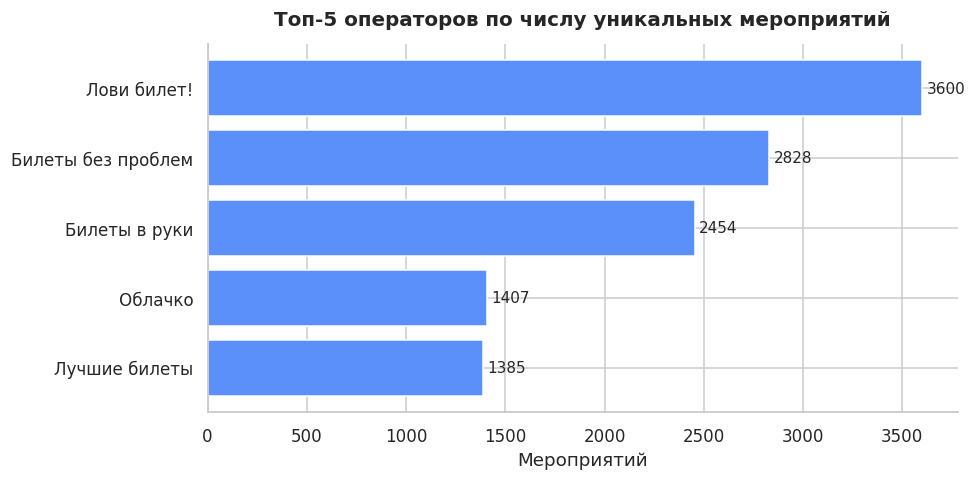

In [30]:
top_events = partners.sort_values('events', ascending=False).head(5)
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(top_events.index[::-1], top_events['events'][::-1], color='#5B8FF9')
ax.bar_label(bars, fmt='%d', padding=3, fontsize=10)
ax.set(title='Топ-5 операторов по числу уникальных мероприятий', xlabel='Мероприятий', ylabel='')
sns.despine()
plt.tight_layout()
plt.show()

`service_name` — билетный оператор, а не организатор мероприятия. По числу мероприятий лидирует «Лови билет!» (3 600, 20.9 %), по заказам — «Билеты без проблем» (31 411, 20.2 %), по выручке — тоже «Билеты без проблем» (12.3 млн ₽, 15.4 %). В топ-5 по выручке входят также «Облачко» (10.5 млн ₽), «Лови билет!» (10.3 млн ₽), «Мой билет» (10.0 млн ₽) и «Весь в билетах» (9.3 млн ₽). Рынок операторов заметно концентрированнее, чем региональный: пять компаний дают 67.8 % мероприятий.

### 3.11 Площадки

In [31]:
venues = (autumn.groupby(['venue_name', 'city_name'])
          .agg(events=('event_id', 'nunique'),
               orders=('order_id', 'size'),
               revenue=('revenue_rub', 'sum')))
top_venues = venues.sort_values('orders', ascending=False).head(5).round(0)
display(top_venues)
print(f'всего площадок: {len(venues)}')

,,events,orders,revenue
venue_name,city_name,,,
"Студия дизайна ""Лестница"" Лимитед",Глиногорск,40,2701,"2,061,021.00"
"Культурный центр ""Общие"" Групп",Глиногорск,85,2369,"1,072,315.00"
"Клуб киноманов ""Верность"" Лтд",Глиногорск,62,2009,"630,793.00"
"Консерватория ""Лестница"" Лтд",Глиногорск,36,1937,"822,865.00"
"Мастерская живого действия ""Гардероб"" Лимитед",Верховино,13,1911,"2,183,218.00"


всего площадок: 2852


Самые загруженные площадки — в Глиногорске: студия «Лестница» (2 701 заказ при 40 мероприятиях), культурный центр «Общие» (2 369 при 85), клуб киноманов «Верность» (2 009), консерватория «Лестница» (1 937). Мастерская «Гардероб» в Верховино при 13 мероприятиях собирает 1 911 заказов и 2.2 млн ₽ — самая высокая выручка на мероприятие в топ-5.

Поле `organizers` содержит обезличенные идентификаторы (`№4893`), поэтому рейтинг организаторов по названиям построить нельзя — это ограничение данных, а не анализа.

## 4. Проверка гипотез

### Гипотеза 1: мобильные пользователи делают больше заказов

- **H₀:** распределение числа заказов на пользователя у мобильных не сдвинуто вправо относительно десктопа.
- **H₁:** у мобильных пользователей число заказов на пользователя больше.

Сравниваем число заказов одного пользователя за осень по группам устройств. Используем односторонний тест Манна—Уитни: он не требует нормальности и устойчив к выбросам. Дополнительно считаем размер эффекта — дельту Клиффа (0.15 — малый эффект, 0.33 — средний, 0.47 — большой).

In [32]:
per_user = (autumn.groupby(['user_id', 'device_type_canonical'])
            .size().rename('orders').reset_index())
mobile = per_user.loc[per_user['device_type_canonical'] == 'mobile', 'orders']
desktop = per_user.loc[per_user['device_type_canonical'] == 'desktop', 'orders']

summary = pd.DataFrame({'mobile': mobile.describe(), 'desktop': desktop.describe()})
display(summary.round(2))

u_stat, p_value = mannwhitneyu(mobile, desktop, alternative='greater')
cliff = 2 * u_stat / (len(mobile) * len(desktop)) - 1
print(f'U = {u_stat:,.0f}, p = {p_value:.2e}, дельта Клиффа = {cliff:.3f}')
print(f'медиана: mobile {mobile.median():.0f}, desktop {desktop.median():.0f}')
print(f'среднее: mobile {mobile.mean():.2f}, desktop {desktop.mean():.2f}')

,mobile,desktop
count,"14,004.00","4,791.00"
mean,9.08,5.98
std,65.34,30.95
min,1.00,1.00
25%,1.00,1.00
50%,2.00,2.00
75%,4.00,4.00
max,"4,165.00","1,378.00"


U = 35,548,943, p = 5.35e-11, дельта Клиффа = 0.060
медиана: mobile 2, desktop 2
среднее: mobile 9.08, desktop 5.98


In [33]:
orders_per_user = frame.groupby('user_id').size()
heavy_users = orders_per_user[orders_per_user > 50].index
light = per_user[~per_user['user_id'].isin(heavy_users)]

mobile_light = light.loc[light['device_type_canonical'] == 'mobile', 'orders']
desktop_light = light.loc[light['device_type_canonical'] == 'desktop', 'orders']
u_stat, p_value = mannwhitneyu(mobile_light, desktop_light, alternative='greater')
cliff = 2 * u_stat / (len(mobile_light) * len(desktop_light)) - 1

print(f'без пользователей с >50 заказов: mobile n={len(mobile_light):,}, desktop n={len(desktop_light):,}')
print(f'медиана: {mobile_light.median():.0f} против {desktop_light.median():.0f}; '
      f'среднее: {mobile_light.mean():.2f} против {desktop_light.mean():.2f}')
print(f'U = {u_stat:,.0f}, p = {p_value:.2e}, дельта Клиффа = {cliff:.3f}')

без пользователей с >50 заказов: mobile n=13,353, desktop n=4,167
медиана: 2 против 1; среднее: 3.45 против 2.34
U = 31,352,566, p = 1.99e-39, дельта Клиффа = 0.127


Гипотеза 1 подтверждается, но эффект небольшой: медиана — 2 заказа на мобильном и 2 на десктопе (без сверхактивных пользователей — 2 и 1), средние — 9.08 и 5.98. Дельта Клиффа 0.06 на всех данных и 0.13 без пользователей с более чем 50 заказами: это малый эффект, а не «в разы больше». P-value здесь почти ничего не доказывает из-за объёма выборки (десятки тысяч наблюдений), поэтому опираться нужно на размер эффекта и медианы.

Важная оговорка: пользователи, покупавшие с обоих устройств, учитываются в обеих группах — их заказы делятся между мобильным и десктопом.

### Гипотеза 2: у мобильных пользователей больше интервал между заказами

- **H₀:** распределение `days_since_prev` у мобильных не сдвинуто вправо.
- **H₁:** интервал между заказами у мобильных больше.

Чтобы интервал относился к одному устройству, исключаем пользователей, покупавших с обоих устройств, а также пользователей с единственным заказом за осень (у них нет предыдущего заказа в выборке). Тест — Манна—Уитни, размер эффекта — дельта Клиффа.

In [34]:
orders_count = autumn.groupby('user_id').size()
multi_order_users = orders_count[orders_count > 1].index

mobile_users = set(autumn.loc[autumn['device_type_canonical'] == 'mobile', 'user_id'])
desktop_users = set(autumn.loc[autumn['device_type_canonical'] == 'desktop', 'user_id'])
hybrid_users = mobile_users & desktop_users

h2 = (autumn[autumn['user_id'].isin(multi_order_users) & ~autumn['user_id'].isin(hybrid_users)]
      .dropna(subset=['days_since_prev']))
mobile_gap = h2.loc[h2['device_type_canonical'] == 'mobile', 'days_since_prev']
desktop_gap = h2.loc[h2['device_type_canonical'] == 'desktop', 'days_since_prev']

print(f'пользователей с обоими устройствами исключено: {len(hybrid_users):,}')
display(pd.DataFrame({'mobile': mobile_gap.describe(), 'desktop': desktop_gap.describe()}).round(2))

u_stat, p_value = mannwhitneyu(mobile_gap, desktop_gap, alternative='greater')
cliff = 2 * u_stat / (len(mobile_gap) * len(desktop_gap)) - 1
print(f'на уровне заказов: median {mobile_gap.median():.1f} / {desktop_gap.median():.1f}, '
      f'mean {mobile_gap.mean():.2f} / {desktop_gap.mean():.2f}')
print(f'U = {u_stat:,.0f}, p = {p_value:.2e}, дельта Клиффа = {cliff:.3f}')
print(f'доля нулевых интервалов: {mobile_gap.eq(0).mean():.1%} / {desktop_gap.eq(0).mean():.1%}')

пользователей с обоими устройствами исключено: 3,183


,mobile,desktop
count,"22,109.00","1,468.00"
mean,10.49,10.21
std,20.79,23.84
min,0.00,0.00
25%,0.00,0.00
50%,1.00,0.00
75%,11.00,5.00
max,146.00,146.00


на уровне заказов: median 1.0 / 0.0, mean 10.49 / 10.21
U = 18,595,268, p = 4.78e-24, дельта Клиффа = 0.146
доля нулевых интервалов: 49.4% / 66.8%


In [35]:
median_by_user = (h2.groupby(['user_id', 'device_type_canonical'])['days_since_prev']
                  .median().rename('median_gap').reset_index())
mobile_med = median_by_user.loc[median_by_user['device_type_canonical'] == 'mobile', 'median_gap']
desktop_med = median_by_user.loc[median_by_user['device_type_canonical'] == 'desktop', 'median_gap']

u_stat, p_value = mannwhitneyu(mobile_med, desktop_med, alternative='greater')
cliff = 2 * u_stat / (len(mobile_med) * len(desktop_med)) - 1
print(f'на уровне пользователя: n={len(mobile_med):,} / {len(desktop_med):,}')
print(f'медиана медианных интервалов: {mobile_med.median():.1f} / {desktop_med.median():.1f} дн.; '
      f'среднее: {mobile_med.mean():.2f} / {desktop_med.mean():.2f}')
print(f'U = {u_stat:,.0f}, p = {p_value:.2e}, дельта Клиффа = {cliff:.3f}')

на уровне пользователя: n=5,501 / 559
медиана медианных интервалов: 2.5 / 0.0 дн.; среднее: 10.14 / 8.26
U = 1,803,796, p = 1.13e-12, дельта Клиффа = 0.173


Гипотеза 2 подтверждается статистически, но эффект малый: медиана интервала — 2.5 дня у мобильных против 0 у десктопа, средние — 10.1 и 8.3 дня, дельта Клиффа 0.17. На уровне заказов средние почти равны (10.5 и 10.2 дня), а медианы 1 и 0. Разница есть, но она невелика, и объяснять её одной «спонтанностью» мобильных покупок нельзя: 49 % мобильных интервалов и 67 % десктопных равны нулю, то есть значительная часть заказов совершается в один день.

Разница средних на уровне заказов и на уровне пользователей — пример псевдорепликации: активные пользователи дают сотни наблюдений и тянут среднее на себя. Поэтому основной вывод делаем по пользовательским медианам.

## 5. Ограничения анализа

- **Сверхактивные пользователи.** В данных есть `user_id` с 9 881 заказом; топ-100 пользователей дают 41.7 % всех заказов при медиане 2 заказа. Это либо тестовые/служебные аккаунты, либо склейка пользователей — перед продуктовыми решениями это нужно выяснить у источника данных.
- **Дробление заказов.** До 105 заказов одного пользователя по одному событию в один день: заказ в выгрузке не всегда равен покупке. Единица анализа «заказ» и «покупка» смешиваются, это влияет на все метрики «на пользователя».
- **Аномальные выгрузки.** 3 сентября, 1 октября, 15 октября и 31 октября часть заказов записана временем загрузки партнёром. Такие строки исключены, но граница «нормального» часа задана эвристикой (в 8 раз выше медианы).
- **`days_since_prev`** рассчитан по всей истории, но выборка обрезана 1 июня — 31 октября: интервалы на границах периода усечены.
- **`total` и `revenue`** различаются в 269 060 строках из 274 775, отношение принимает дискретные значения от 6 до 50. В анализе используется `revenue`; что именно означает `total`, в описании данных не раскрыто.
- **Организаторы** обезличены (`№4893`), поэтому рейтинг организаторов по названиям невозможен.
- **Нет данных об отменах, возвратах билетов и показах** — анализ только по фактам оформления заказов.
- Названия регионов и площадок выглядят синтетическими; выводы по географии стоит воспринимать как учебные, а не как рыночные.

## 6. Итоговый вывод

- За период 1 июня — 31 октября 2024 года обработано 290 849 заказов; после очистки (возвраты, выбросы, аномальные выгрузки) в анализ вошло 274 775 заказов на 146.7 млн ₽.
- Спрос растёт каждый месяц: 33 974 заказа в июне, 44 585 в августе, 65 759 в сентябре (+47.5 %) и 90 045 в октябре (+36.9 %). В среднем за день — с 1 132 до 2 905 заказов. Активная аудитория осенью растёт с 565 до 950 пользователей в день.
- Структура афиши смещается к театру: доля заказов 20.1 % → 27.3 %, доля выручки 21.1 % → 25.7 %. Концерты остаются лидером (42.5 % → 38.3 % заказов, 59.8 % → 54.6 % выручки), спорт растёт с 2.5 % до 6.8 % заказов.
- Средняя цена билета осенью падает почти во всех категориях: концерты −7.3 % (299 → 277 ₽), театр −16.6 % (212 → 177 ₽), ёлки −16.9 %. Растут спорт (+17.3 %), стендап (+6.1 %), выставки (+4.5 %). Суммарная выручка при этом растёт за счёт объёма, а не цены.
- Заказы распределены по будням: лидер — пятница (24 837 заказов, 12.7 млн ₽), затем четверг и среда; минимум в воскресенье. Выходные дают 26.2 % заказов.
- 81 % заказов — с мобильных устройств, и эта доля не зависит от сезона.
- В топ-5 регионов входят Каменевский регион (24.7 % мероприятий и 28.1 % заказов), Североярская, Широковская области, Светополянский округ и Речиновская область. Пять операторов дают около 60 % мероприятий; по выручке лидирует «Билеты без проблем» (15.4 %).
- Гипотеза 1 подтверждается со слабым эффектом: медианы числа заказов 2 и 2 (2 и 1 без сверхактивных пользователей), дельта Клиффа 0.06–0.13.
- Гипотеза 2 подтверждается со слабым эффектом: медианный интервал 2.5 дня у мобильных против 0 у десктопа, средние 10.1 и 8.3 дня, дельта Клиффа 0.17.

## 7. Рекомендации

- **Театр — главная точка роста.** Доля и заказов, и выручки растёт, но средняя цена билета падает на 16.6 %. Стоит проверить, не каннибализируют ли дешёвые осенние показы выручку, и протестировать отдельные ценовые сегменты.
- **Концерты.** Цена снижается умеренно (−7.3 %), а доля выручки падает сильнее — потому что растут другие категории. Отдельного «обвала» нет; прежний вывод о падении на 69 % был ошибкой конвертации валют.
- **Спорт.** Доля заказов выросла с 2.5 % до 6.8 %, цена — на 17.3 %. Направление перспективное, но эффект скромнее, чем показывали неочищенные данные.
- **Пятница и четверг** — пик по заказам и выручке. Промо-активность логично ставить на начало недели и воскресенье, где спрос минимален.
- **Мобильный канал** даёт 81 % заказов, но интервалы между покупками у мобильных больше: стоит проверить воронку повторных покупок в приложении (пуши, напоминания, подборки).
- **Десктоп** — 19 % заказов; прежде чем вкладываться в отдельные акции, проверьте, не является ли десктоп каналом покупки для семейных и корпоративных заказов (там больше билетов на заказ).
- **Перед продуктовыми решениями** выясните природу сверхактивных `user_id` и правило формирования `total`: сейчас они искажают метрики «на пользователя».